# Identity continuity: % frames with a wrong identity, Shiv vs Kaden (all videos)

The per-frame checks in `Tracking_comparison_Shiv_Kaden.ipynb` flag the frame where something goes wrong, but not the frames afterwards during which a label stays on the wrong fish. This notebook decodes, for every frame, **which fish each label is actually on**, and from that computes **% frames with a wrong identity**.

### Method (`identity_hmm.py`)
In each frame, the true identity of the 4 labels is one of the 24 possible permutations. A Viterbi decoder finds the most likely permutation over time from:

1. **Motion continuity (where a switch can happen).** Identities can only change:
   * at a **contact**: centroids closer than half the sum of the two fish's lengths. This has a small prior, 10⁻⁶ per frame.
   * where two labels **exchange positions** from one frame to the next, i.e. each label is far closer to the other's previous position. This is physically impossible for real fish, so it's treated as a near-certain label swap.
   * where a label **reappears after a gap or teleports**. It may then swap with a label near its old or new position (prior 0.1).

   Everywhere else the identity is carried forward unchanged.
2. **Size (which assignment fits).** The four fish differ in size. Each label's mask area, corrected for position (fish look smaller near the walls), is scored against every fish's typical area. Frames failing a bad-frame check (and Kaden's occluded frames) carry no size information.

The typical sizes and the position correction are re-estimated from the decoded identities, and the decoding is run twice. Labels are named by the tracker, so by definition the decoder can't detect a label that is wrong for the **whole** video. It measures **switches**.

### Evidence behind each episode
| evidence | meaning | counted in % wrong identity |
|---|---|---|
| stacked | at least 5 s long, with the two fish lying on top of each other for most of it (centroids within a quarter of their summed lengths). The labels exchange positions as the stack forms and breaks up, but which fish is which in between can't be checked, by eye or by size | no, reported as "% in stacks (unverifiable)" |
| motion | two of the episode's labels exchange positions from one frame to the next at its start or end (impossible for real fish), and no label's size contradicts it | yes |
| motion, size disagrees | an exchange at one end, but every label with size data keeps its own fish's size for the whole episode. Typically a one-frame centroid glitch (Kaden's full-body centroids) after which the decoder has no chance to switch back until the fish next touch | no, only in "all decoded" |
| size, both labels | every swapped label is closer in size to the fish it was decoded onto than to its own | yes |
| size, one label | only one label looks like the other fish. This is also what happens when a fish simply looks smaller somewhere (e.g. Kaden's fish C along the top wall is 0.70–0.73× its usual size, which is exactly fish D's size) | no, only in "all decoded" |

The size test for an episode only uses frames where the fish is in open water on its own: at least 120 px from the image edge and not in contact with another fish. Along the walls the size changes in a fish-specific way that the wall correction can't fully undo.
| none | neither | no |

### Metrics per video
| metric | meaning |
|---|---|
| % good (per-frame checks) | as in the comparison notebook: all 4 fish pass untracked / centroid jump / area jump / fragmented / overlap |
| **% wrong identity** | frames inside a **confirmed** wrong-identity episode (see *evidence* below): at least one label is on another fish |
| % in stacks (unverifiable) | frames inside 'stacked' episodes |
| % wrong identity, all decoded | the same, counting every decoded episode, including stacks and ones backed only by one label looking the wrong size |
| **% good and correct identity** | good by the per-frame checks *and* correct identity, the strictest usable-frame measure |
| swaps per hour | number of wrong-identity episodes per hour of video |
| median / longest swap (s) | duration of the wrong-identity episodes |
| % mask lost / merged | at least one usable-looking mask is < 0.5× or > 1.6× its fish's typical area (a fish's mask lost to a fragment, or two fish under one label). Reported only, not part of good. |
| planted-swap recall | positive control: 5 swaps of 5–60 s planted per video (two labels exchange all data between two contact frames); share of planted frames the decoder marks wrong |

In [1]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

os.chdir('/Volumes/Lenca_SSD/github/social_electric_fish')
import tracking_compare as tc
import identity_hmm as ih
import identity_check as ic
%matplotlib inline
pd.set_option('display.precision', 2)
OUT = os.path.join('figures', 'identity_continuity')
COL = tc.TRACKER_COLOR

RESULTS = os.path.join(OUT, 'results.pkl')
if not os.path.exists(RESULTS):          # ~5 min with 4 workers
    ih.run_all()
with open(RESULTS, 'rb') as f:
    res = {(r['tracker'], r['recording']): r for r in pickle.load(f)}
recs = tc.find_recordings()
ts = lambda f: ic.mmss(f, 50)

## Validation

### 1. The two swaps found by eye in Shiv `2024-10-23T15_18_28`
| by eye | decoded |
|---|---|
| 3:42.4 – 3:43.3: label 3's mask absorbs fish 0, then label 3 jumps onto fish 0 while label 0 is a fragment (you spotted this one) | see below |
| 6:46.3 – 7:44.5: labels 2↔3 (and 0 for the first 8 s) | see below |

In [2]:
r = res[('Shiv', '2024-10-23T15_18_28')]
ep = r['episodes'].copy()
ep.insert(0, 'from', ep.start.map(ts)); ep.insert(1, 'to', ep.end.map(ts))
ep[['from', 'to', 'duration_s', 'labels', 'main_perm']]

,from,to,duration_s,labels,main_perm
0,1:28.1,1:30.7,2.58,0+3,3→0 0→3
1,2:14.1,2:14.6,0.54,0+3,3→0 0→3
2,3:42.4,3:43.2,0.84,0+3,3→0 0→3
3,5:54.9,5:55.7,0.84,0+3,3→0 0→3
4,6:46.3,7:44.6,58.40,0+2+3,2→3 3→2
5,9:53.4,9:55.8,2.40,0+3,3→0 0→3
6,10:00.9,10:01.5,0.68,1+3,1→3 3→1
7,10:54.7,10:55.3,0.56,0+3,3→0 0→3
8,11:43.6,11:44.7,1.08,2+3,2→3 3→2
9,13:50.2,13:50.8,0.62,2+3,2→3 3→2


### 2. Decoded episodes checked by eye
Each decoded episode in two Shiv videos was checked in the annotated video, frame by frame around its start and end (2026-10-29). Colours: label 1 pink, 2 green, 3 yellow, 0 blue.

| video | episode | what the video shows | real swap? |
|---|---|---|---|
| 15:18 | 1:28.1 – 1:30.7 (0+3) | yellow's mask spreads over two fish while blue is lost; blue then sits on yellow's fish until they swap back at 1:30.7 | yes |
| 15:18 | 2:14.1 – 2:14.6 (0+3) | blue and yellow swim side by side; their labels swap and swap back | yes |
| 15:18 | 3:42.4 – 3:43.2 (0+3) | the case you spotted | yes |
| 15:18 | 5:54.9 – 5:55.7 (0+3) | blue on the larger fish while the two cross | yes |
| 15:18 | 6:46.3 – 7:44.6 (2+3+0) | the confirmed 58 s swap | yes |
| 15:18 | 9:53.4 – 9:55.8 (0+3) | blue on the larger fish for 2.4 s after a crossing under pink | yes (my earlier 3-frame check missed it) |
| 15:18 | 10:00.9 – 10:01.5 (1+3) | while pink and yellow cross, yellow is on the long fish and pink on the shorter | yes |
| 15:18 | 10:54.7 – 10:55.3 (0+3) | yellow covers two fish, then blue and yellow swap and swap back | yes |
| 15:18 | 11:43.6 – 11:44.7 (2+3) | yellow jumps onto the corner fish and green onto a fish in the middle for 1.1 s | yes (my earlier check missed it) |
| 15:18 | 13:50.2 – 13:50.8 (2+3) | green and yellow cross; labels swap, then swap back | yes |
| 15:18 | 19:11.6 – 19:12.1 (0+3) | yellow covers both fish, then blue and yellow swap and swap back | yes |
| 21:56 | 1:44.6 – 1:45.3 (0+3) | blue and yellow cross; labels swap for 0.7 s | yes |
| 21:56 | 3:13.7 – 3:14.7 (1+2) | pink and green cross at the bottom edge, partly out of view | unclear |
| 21:56 | 8:56.2 – 8:56.6 (0+2) | green's mask merges with blue's; blue on the larger fish for 0.4 s | yes |
| 21:56 | 9:58.1 – 9:58.3 (0+3) | blue and yellow swim side by side; labels swap for 0.3 s | yes |
| 21:56 | 19:24.9 – 19:25.2 (2+3) | green covers two fish, then green and yellow are on each other's fish for 0.3 s | yes (sizes 1.57× apart) |

**15 of 16 decoded episodes are real swaps; 1 is unclear; none is a clear false alarm.** Most are brief swaps (0.3–2.6 s) while two fish cross, which the earlier size-only checks (1–2 s smoothing) could not see.

### 3. Kaden's longest episodes, checked by eye (letters A red, B orange, C yellow, D blue)
| video | episode | what the video shows | verdict | evidence now |
|---|---|---|---|---|
| 17:56 | 0:00.0 – 3:31.1 (211 s, C+D) | C rests on the top-left wall and looks small there. Measured in open water on its own, C is the bigger fish both before (1948 vs 1439 px) and after (1631 vs 1161 px) | **false alarm** (wall) | size, one label: not counted |
| 16:36 | 10:23.6 – 11:42.2 (79 s, C+D) | C sits along the top wall for the whole episode and looks as small as D there; D stays normal | **false alarm** (wall) | none: not counted |
| 16:36 | 5:33.6 – 6:05.2 (32 s) | same pattern | **false alarm** (wall) | none: not counted |
| 16:56 | 16:50.0 – 17:04.3 (14 s, A+B) | at 17:04.3 orange B is on the long fish and red A takes it back at 17:04.4; both labels' sizes agree | **real swap** | motion: counted |
| 16:56 | 17:24.7 – 18:03.4 (39 s, C+D) | C and D lie on top of each other the whole time and separate at 18:03.4 | unverifiable | stacked: not counted |
| 17:16 | 18:18.0 – 18:41.5 (24 s, C+D) | C and D stacked under A | unverifiable | stacked |
| 16:56 | 11:36.6 – 11:58.2 (22 s, C+D) | C and D stacked | unverifiable | stacked |
| 18:36 | 13:18.8 – 13:38.3 (20 s, C+D) | C and D meet, then stay stacked | unverifiable | stacked |
| 17:16 | 19:13.3 – 19:29.1 (16 s, C+D) | C and D stacked | unverifiable | stacked |

Kaden's two smallest fish, C and D, often lie on top of each other for 10–40 s. Within such a stack the labels' positions exchange, but neither eye nor size can tell which fish is which.

### 4. Planted swaps (positive control, every video)

In [3]:
ctrl = pd.DataFrame([dict(tracker=t, recording=rec, planted=len(r['planted']),
                          recall=100 * r['planted_recall'],
                          fully_found=sum(d > 0.9 for d in r['planted_detected']),
                          false_wrong_pct=100 * r['planted_false'])
                     for (t, rec), r in res.items()])
display(Markdown(f"Planted swaps: **{ctrl.planted.sum()}** in {len(ctrl)} videos; frames recovered: "
                 f"**{np.average(ctrl.recall, weights=ctrl.planted):.1f}%**; swaps more than 90% recovered: "
                 f"**{ctrl.fully_found.sum()} / {ctrl.planted.sum()}**; extra wrong frames outside the planted swaps: "
                 f"**{ctrl.false_wrong_pct.max():.2f}%** at most."))
display(ctrl.sort_values('false_wrong_pct', ascending=False).head(3))
ctrl.groupby('tracker')[['planted', 'fully_found', 'recall', 'false_wrong_pct']].agg(
    {'planted': 'sum', 'fully_found': 'sum', 'recall': 'mean', 'false_wrong_pct': 'max'})

Planted swaps: **140** in 28 videos; frames recovered: **100.0%**; swaps more than 90% recovered: **139 / 140**; extra wrong frames outside the planted swaps: **7.51%** at most.

,tracker,recording,planted,recall,fully_found,false_wrong_pct
25,Kaden,2024-02-20T17_36_24,5,100.0,5,7.51
24,Kaden,2024-02-20T17_16_24,5,100.0,4,1.18
17,Kaden,2024-02-20T14_56_23,5,100.0,5,0.33


,planted,fully_found,recall,false_wrong_pct
tracker,,,,
Kaden,70,69,100.00,7.51
Shiv,70,70,99.98,0.00


## Final metrics per video

In [4]:
rows, all_ep = [], []
for r0 in recs.itertuples():
    k = (r0.tracker, r0.recording)
    r = res[k]
    fps = r['fps']
    flags = tc.frame_flags(tc.load_metrics(*k, r0.path)['metrics'])
    bad = tc.bad_frames(flags).values
    wrong = r['wrong_confirmed']
    n = len(wrong)
    stack = np.zeros(n, bool)
    for e in r['episodes'][r['episodes'].evidence == 'stacked'].itertuples():
        stack[e.start:e.end + 1] = True
    A = ih.arrays(*k, r0.path)
    true = np.array(ih.PERMS)[r['state']]
    rel = A['area'] / r['ref'][true]
    looks_ok = np.isfinite(A['area']) & ~np.stack(
        [flags.xs(l, axis=1, level='fish')[['untracked', 'centroid_jump', 'area_jump', 'overlap']].any(axis=1).values
         for l in A['fish']], 1)
    lost_merged = ((rel < 0.5) | (rel > 1.6)) & looks_ok
    ep_all = r['episodes']
    ep = ep_all[ep_all.evidence.isin(ih.CONFIRMED)]
    rows.append(dict(tracker=r0.tracker, group=r0.group, recording=r0.recording, minutes=n / fps / 60,
                     pct_good=100 * (1 - bad.mean()),
                     pct_wrong_identity=100 * wrong.mean(),
                     pct_stacked=100 * stack.mean(),
                     pct_wrong_identity_all=100 * r['wrong'].mean(),
                     pct_good_and_correct=100 * (~bad & ~wrong).mean(),
                     swaps=len(ep), swaps_per_hour=len(ep) / (n / fps / 3600),
                     median_swap_s=ep.duration_s.median() if len(ep) else 0.0,
                     longest_swap_s=ep.duration_s.max() if len(ep) else 0.0,
                     pct_mask_lost_or_merged=100 * lost_merged.any(axis=1).mean(),
                     planted_recall=100 * r['planted_recall']))
    if len(ep_all):
        e = ep_all.copy()
        e.insert(0, 'recording', r0.recording); e.insert(0, 'tracker', r0.tracker)
        e['from'] = e.start.map(ts); e['to'] = e.end.map(ts)
        all_ep.append(e)
final = pd.DataFrame(rows)
episodes = pd.concat(all_ep, ignore_index=True)
episodes['confirmed'] = episodes.evidence.isin(ih.CONFIRMED)
final.to_csv(os.path.join(OUT, 'final_metrics_per_video.csv'), index=False)
episodes.to_csv(os.path.join(OUT, 'wrong_identity_episodes.csv'), index=False)
names = {'pct_good': '% good (per-frame checks)', 'pct_wrong_identity': '% wrong identity',
         'pct_stacked': '% in stacks (unverifiable)', 'pct_wrong_identity_all': '% wrong identity, all decoded',
         'pct_good_and_correct': '% good and correct identity', 'swaps': 'swaps',
         'swaps_per_hour': 'swaps / hour', 'median_swap_s': 'median swap (s)', 'longest_swap_s': 'longest swap (s)',
         'pct_mask_lost_or_merged': '% mask lost / merged', 'planted_recall': 'planted-swap recall (%)'}
(final.rename(columns=names).style.format(precision=2).hide(axis='index')
 .background_gradient(subset=['% good and correct identity'], cmap='Blues', vmin=50, vmax=100))

tracker,group,recording,minutes,% good (per-frame checks),% wrong identity,% in stacks (unverifiable),"% wrong identity, all decoded",% good and correct identity,swaps,swaps / hour,median swap (s),longest swap (s),% mask lost / merged,planted-swap recall (%)
Shiv,Group_01,2024-02-20T18_56_25,20.00,89.50,0.96,0.95,1.91,89.06,6,18.00,1.60,4.92,3.56,100.00
Shiv,Group_01,2024-02-20T21_16_26,20.00,94.46,1.30,0.00,1.32,93.35,2,6.00,7.79,12.18,1.03,99.69
Shiv,Group_01,2024-02-20T20_16_25,20.00,93.49,1.62,0.00,1.62,91.99,5,15.00,1.06,10.68,2.86,100.00
Shiv,Group_01,2024-02-20T21_56_26,20.00,91.60,0.23,0.00,0.23,91.40,5,15.00,0.44,1.02,1.41,100.00
Shiv,Group_01,2024-02-20T22_56_26,20.00,98.33,0.00,0.00,0.00,98.33,0,0.00,0.00,0.00,0.60,100.00
Shiv,Group_02,2024-10-23T15_18_28,20.00,78.57,5.75,0.00,5.75,74.83,11,33.00,0.84,58.40,3.16,100.00
Shiv,Group_02,2024-10-23T16_18_28,20.00,89.37,0.38,0.00,0.38,89.14,4,12.00,1.23,1.90,1.84,100.00
Shiv,Group_02,2024-10-23T16_38_28,20.00,93.01,3.31,0.00,3.79,90.00,10,30.00,2.28,17.62,2.02,100.00
Shiv,Group_02,2024-10-23T18_18_29,20.00,86.91,0.46,0.00,0.46,86.63,4,12.00,0.60,4.02,1.44,100.00
Shiv,Group_02,2024-10-23T19_18_30,20.00,93.43,1.40,0.00,1.40,92.33,8,24.00,2.32,4.44,4.20,100.00


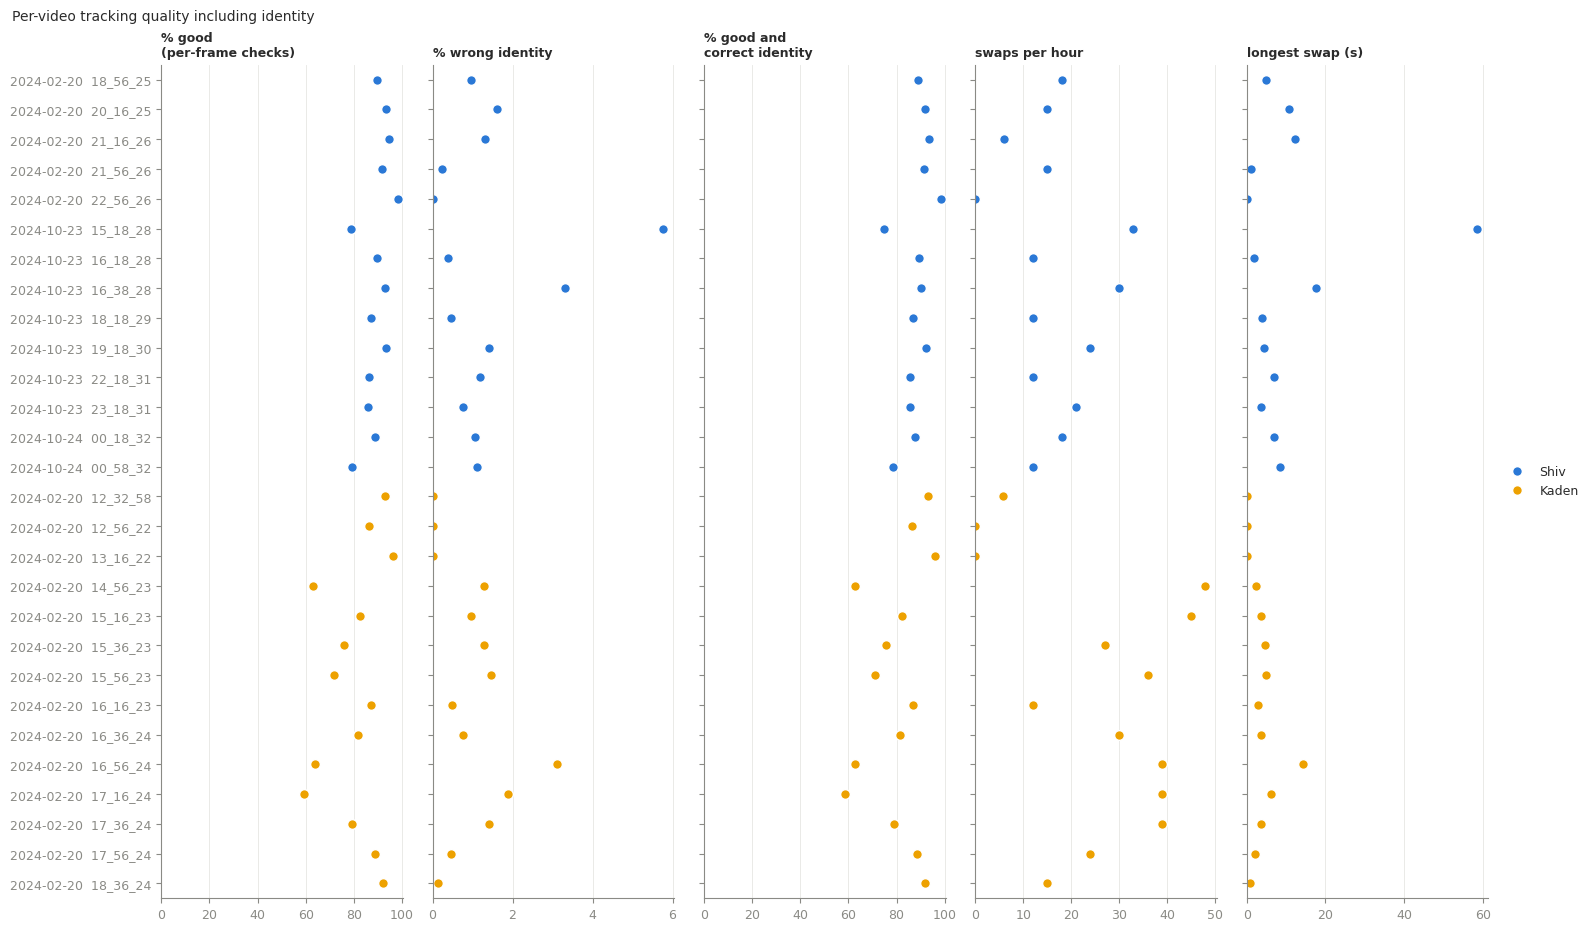

In [5]:
order = final.sort_values(['tracker', 'recording'], ascending=[False, True]).reset_index(drop=True)
specs = [('pct_good', '% good\n(per-frame checks)'), ('pct_wrong_identity', '% wrong identity'),
         ('pct_good_and_correct', '% good and\ncorrect identity'), ('swaps_per_hour', 'swaps per hour'),
         ('longest_swap_s', 'longest swap (s)')]
fig, axes = plt.subplots(1, len(specs), figsize=(16, 0.28 * len(order) + 1.6), sharey=True)
y = np.arange(len(order))
for ax, (col, title) in zip(axes, specs):
    for t in tc.TRACKERS:
        m = (order.tracker == t).values
        ax.plot(order[col].values[m], y[m], 'o', ms=7, color=COL[t], mec='white', mew=1, label=t)
    ax.set_title(title, loc='left', fontsize=9)
    ax.set_xlim(left=0)
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(y, order.recording.str.replace('T', '  '))
axes[0].set_ylim(len(order) - 0.5, -0.5)
axes[-1].legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
fig.suptitle('Per-video tracking quality including identity', x=0.01, ha='left', fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(OUT, 'final_metrics_per_video.png'), dpi=150)

## Across all videos

In [6]:
def pooled(sub):
    w = sub.minutes
    return pd.Series({'videos': len(sub), 'hours': w.sum() / 60,
                      '% good (per-frame checks)': np.average(sub.pct_good, weights=w),
                      '% wrong identity': np.average(sub.pct_wrong_identity, weights=w),
                      '% in stacks (unverifiable)': np.average(sub.pct_stacked, weights=w),
                      '% wrong identity, all decoded': np.average(sub.pct_wrong_identity_all, weights=w),
                      '% good and correct identity': np.average(sub.pct_good_and_correct, weights=w),
                      'swaps / hour': sub.swaps.sum() / (w.sum() / 60),
                      'median swap (s)': episodes[episodes.recording.isin(sub.recording) & episodes.confirmed &
                                                  episodes.tracker.isin(sub.tracker)].duration_s.median(),
                      'longest swap (s)': sub.longest_swap_s.max(),
                      '% mask lost / merged': np.average(sub.pct_mask_lost_or_merged, weights=w),
                      'planted-swap recall (%)': sub.planted_recall.mean()})

overall = pd.DataFrame({
    'Shiv, all': pooled(final[final.tracker == 'Shiv']),
    'Shiv, group 1': pooled(final[(final.tracker == 'Shiv') & (final.group == 'Group_01')]),
    'Shiv, group 2': pooled(final[(final.tracker == 'Shiv') & (final.group == 'Group_02')]),
    'Kaden (group 1)': pooled(final[final.tracker == 'Kaden']),
}).T
overall.to_csv(os.path.join(OUT, 'final_metrics_overall.csv'))
overall

,videos,hours,% good (per-frame checks),% wrong identity,% in stacks (unverifiable),"% wrong identity, all decoded",% good and correct identity,swaps / hour,median swap (s),longest swap (s),% mask lost / merged,planted-swap recall (%)
"Shiv, all",14.0,4.67,89.18,1.40,0.07,1.53,88.18,16.29,1.22,58.40,2.39,99.98
"Shiv, group 1",5.0,1.67,93.48,0.82,0.19,1.01,92.83,10.80,1.09,12.18,1.89,99.94
"Shiv, group 2",9.0,3.00,86.79,1.71,0.00,1.81,85.60,19.33,1.38,58.40,2.67,100.00
Kaden (group 1),14.0,4.50,79.54,0.98,1.84,5.08,79.23,26.42,0.82,14.40,4.25,100.00


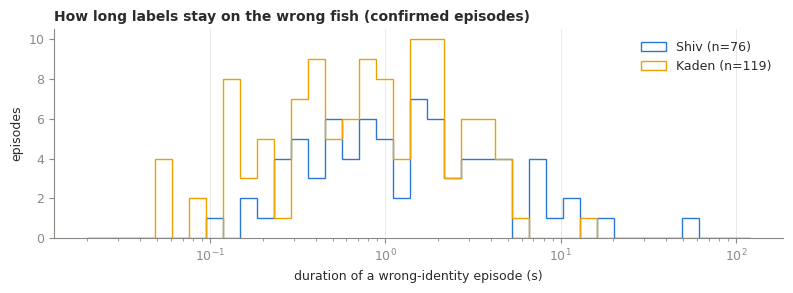

In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
bins = np.logspace(np.log10(0.02), np.log10(120), 40)
for t in tc.TRACKERS:
    d = episodes[(episodes.tracker == t) & episodes.confirmed].duration_s
    ax.hist(d, bins=bins, histtype='step', lw=1.8, color=COL[t], label=f'{t} (n={len(d)})')
ax.set_xscale('log')
ax.set_xlabel('duration of a wrong-identity episode (s)')
ax.set_ylabel('episodes')
ax.legend()
ax.grid(axis='y', visible=False)
ax.set_title('How long labels stay on the wrong fish (confirmed episodes)', loc='left')
fig.tight_layout()
fig.savefig(os.path.join(OUT, 'swap_durations.png'), dpi=150)

## Longest wrong-identity episodes

The 10 longest episodes per tracker (all decoded, with their evidence), times in m:ss. Every episode is in `figures/identity_continuity/wrong_identity_episodes.csv`.

In [8]:
for t in tc.TRACKERS:
    display(Markdown(f'**{t}**'))
    display(episodes[episodes.tracker == t].sort_values('duration_s', ascending=False).head(10)[
        ['recording', 'from', 'to', 'duration_s', 'labels', 'main_perm', 'size_match', 'evidence']].reset_index(drop=True))
display(Markdown('**Episodes by evidence** (count, total seconds)'))
display(episodes.groupby(['tracker', 'evidence']).duration_s.agg(['count', 'sum']).round(1))

**Shiv**

,recording,from,to,duration_s,labels,main_perm,size_match,evidence
0,2024-10-23T15_18_28,6:46.3,7:44.6,58.40,0+2+3,2→3 3→2,no data,motion
1,2024-10-23T16_38_28,14:39.4,14:57.0,17.62,2+3,2→3 3→2,2/2,motion
2,2024-02-20T21_16_26,9:09.9,9:22.1,12.18,0+3,3→0 0→3,2/2,motion
3,2024-02-20T20_16_25,0:00.0,0:10.7,10.68,2+3,2→3 3→2,2/2,"size, both labels"
4,2024-10-24T00_58_32,11:08.2,11:16.8,8.56,0+3,3→0 0→3,1/2,motion
5,2024-02-20T20_16_25,3:26.7,3:33.9,7.28,1+2,1→2 2→1,1/1,motion
6,2024-10-24T00_18_32,14:59.3,15:06.2,6.92,0+1+2,1→2 2→1,1/1,motion
7,2024-10-23T22_18_31,6:06.4,6:13.3,6.88,2+3,2→3 3→2,2/2,"size, both labels"
8,2024-10-23T22_18_31,7:39.1,7:45.9,6.84,2+3,2→3 3→2,1/1,motion
9,2024-02-20T18_56_25,9:18.7,9:24.8,6.18,0+3,3→0 0→3,no data,stacked


**Kaden**

,recording,from,to,duration_s,labels,main_perm,size_match,evidence
0,2024-02-20T17_56_24,0:00.0,3:31.1,211.14,2+3,2→3 3→2,1/2,"size, one label"
1,2024-02-20T16_36_24,10:23.6,11:42.2,78.62,2+3,2→3 3→2,0/1,none
2,2024-02-20T16_56_24,17:24.7,18:03.4,38.66,2+3,2→3 3→2,no data,stacked
3,2024-02-20T16_36_24,5:33.6,6:05.2,31.54,0+1+2+3,2→3 3→2,0/1,none
4,2024-02-20T17_36_24,17:22.7,17:52.8,30.12,2+3,2→3 3→2,0/2,"motion, size disagrees"
5,2024-02-20T17_16_24,18:18.0,18:41.5,23.52,2+3,2→3 3→2,no data,stacked
6,2024-02-20T16_56_24,11:36.6,11:58.2,21.54,2+3,2→3 3→2,no data,stacked
7,2024-02-20T18_36_24,13:18.8,13:38.3,19.58,2+3,2→3 3→2,no data,stacked
8,2024-02-20T15_16_23,4:09.2,4:27.6,18.42,2+3,2→3 3→2,0/2,stacked
9,2024-02-20T17_16_24,19:13.3,19:29.1,15.82,2+3,2→3 3→2,no data,stacked


**Episodes by evidence** (count, total seconds)

count    sum
tracker evidence                            
Kaden   motion                    119  158.5
        motion, size disagrees      2   34.3
        none                        4  121.2
        size, one label             1  211.1
        stacked                    27  299.1
Shiv    motion                     74  216.9
        motion, size disagrees      2    5.8
        none                        3    5.2
        size, both labels           2   17.6
        stacked                     2   11.4

In [9]:
# clips of the 3 longest confirmed episodes per tracker (from 3 s before to 3 s after)
clips = []
for t in tc.TRACKERS:
    top = episodes[(episodes.tracker == t) & episodes.confirmed].sort_values('duration_s', ascending=False).head(3)
    for e in top.itertuples():
        mp4 = recs[(recs.tracker == t) & (recs.recording == e.recording)].annotated_mp4.iloc[0]
        if mp4 is None:
            clips.append(dict(tracker=t, recording=e.recording, episode=f"{ts(e.start)}-{ts(e.end)}", clip='no annotated video'))
            continue
        s = max(e.start - 150, 0); n = e.end + 150 - s
        name = f'{t}_{e.recording}_{ts(e.start).replace(":", "m")}.mp4'
        p = tc.make_clip(mp4, s, n, 50, os.path.join(OUT, 'clips', name),
                         f'{t} {e.recording}  wrong identity {ts(e.start)}-{ts(e.end)} ({e.labels})', np.zeros(n, bool))
        clips.append(dict(tracker=t, recording=e.recording, episode=f'{ts(e.start)}-{ts(e.end)}', clip=p))
pd.DataFrame(clips)

,tracker,recording,episode,clip
0,Shiv,2024-10-23T15_18_28,6:46.3-7:44.6,figures/identity_continuity/clips/Shiv_2024-10...
1,Shiv,2024-10-23T16_38_28,14:39.4-14:57.0,figures/identity_continuity/clips/Shiv_2024-10...
2,Shiv,2024-02-20T21_16_26,9:09.9-9:22.1,no annotated video
3,Kaden,2024-02-20T16_56_24,16:50.0-17:04.3,figures/identity_continuity/clips/Kaden_2024-0...
4,Kaden,2024-02-20T17_16_24,1:15.2-1:21.3,figures/identity_continuity/clips/Kaden_2024-0...
5,Kaden,2024-02-20T15_56_23,4:55.2-5:00.0,figures/identity_continuity/clips/Kaden_2024-0...


## Summary

In [10]:
o = overall
lines = []
for name in o.index:
    lines.append(f"* **{name}**: {o.loc[name, '% good (per-frame checks)']:.1f}% good by the per-frame checks; "
                 f"**{o.loc[name, '% wrong identity']:.2f}%** of frames with a confirmed wrong identity "
                 f"(+{o.loc[name, '% in stacks (unverifiable)']:.2f}% in unverifiable stacks; {o.loc[name, '% wrong identity, all decoded']:.2f}% counting every decoded episode) "
                 f"({o.loc[name, 'swaps / hour']:.0f} swaps/hour, median {o.loc[name, 'median swap (s)']:.1f} s, longest {o.loc[name, 'longest swap (s)']:.0f} s); "
                 f"**{o.loc[name, '% good and correct identity']:.1f}%** good and correct.")
display(Markdown('\n'.join(lines)))

* **Shiv, all**: 89.2% good by the per-frame checks; **1.40%** of frames with a confirmed wrong identity (+0.07% in unverifiable stacks; 1.53% counting every decoded episode) (16 swaps/hour, median 1.2 s, longest 58 s); **88.2%** good and correct.
* **Shiv, group 1**: 93.5% good by the per-frame checks; **0.82%** of frames with a confirmed wrong identity (+0.19% in unverifiable stacks; 1.01% counting every decoded episode) (11 swaps/hour, median 1.1 s, longest 12 s); **92.8%** good and correct.
* **Shiv, group 2**: 86.8% good by the per-frame checks; **1.71%** of frames with a confirmed wrong identity (+0.00% in unverifiable stacks; 1.81% counting every decoded episode) (19 swaps/hour, median 1.4 s, longest 58 s); **85.6%** good and correct.
* **Kaden (group 1)**: 79.5% good by the per-frame checks; **0.98%** of frames with a confirmed wrong identity (+1.84% in unverifiable stacks; 5.08% counting every decoded episode) (26 swaps/hour, median 0.8 s, longest 14 s); **79.2%** good and correct.